# Notebook 26: Desacoplamiento por Sistema Mineral y Reentrenamiento Nacional
## Arquitectura de Ensamble de Expertos por Tipología Metalogénica (*Multi-System Mixture of Experts*)

---

## 1. Fundamento Geocientífico: La Península Ibérica como Mosaico de Sistemas Minerales Contrariados
A lo largo de los cuadernos anteriores (NB 19 a NB 25), el modelo predictivo nacional alcanzó cotas sobresalientes de discriminación espacial (*in-sample* Top 1% en 60.0%), pero mantuvo una barrera persistente en la **generalización ciega out-of-fold** (~35-40% en Top 20% y 11-15% en Top 5%). 

El diagnóstico cuantitativo revela la **causa raíz**:
1. **Distribución asimétrica de los datos de entrenamiento:** De los 787 indicios auríferos de la base nacional, más del 60% se concentran en Asturias y León (Macizo Ibérico noroccidental), dominados por **oro orogénico varisco** encajado en pizarras y esquistos verdes paleozoicos.
2. **Transferencia Negativa (*Negative Transfer*) en Árboles Monolíticos:** Un modelo monolítico basado en árboles de decisión (LightGBM) genera particiones ortogonales en el espacio de características. Al estar abrumadoramente sesgado hacia el Noroeste, las ramas dominantes aprenden que si una celda carece de pizarras paleozoicas (`litologia_u008`) o facies de esquistos verdes (`afinidad_esquistos_verdes`), su favorabilidad debe colapsar a valores cercanos a cero.
3. **El conflicto tipológico en validación ciega:** Cuando una rotación territorial evalúa distritos ajenos al dominio orogénico del Noroeste (por ejemplo, el distrito epitermal neógeno de **Cabo de Gata / Rodalquilar** en Almería, los sulfuros masivos de la **Faja Pirítica / Ossa Morena** en Huelva/Badajoz, o los grandes paleoplaceres y terrazas fluviales de **Las Médulas / Valdería**), el modelo monolítico los penaliza severamente porque sus controles geológicos son diametralmente opuestos a los del Noroeste.

### La Solución Geológica: Desacoplamiento por Sistema Mineral (*Mineral Systems Decoupling*)
En la geología económica moderna (McCuaig et al., 2010; Wyborn et al., 1994; Porwal & Kreuzer, 2010), la prospectividad de un territorio no se modela como un bloque ciego homogéneo, sino desacoplando los **sistemas minerales fundamentales**:

1. **Sistema I: Oro Orogénico / Mesotermal Varisco en Roca (y Skarns asociados):**
   * *Controles:* Cizallas dúctil-frágiles, gradiente Bouguer profundo, litologías pizarras/cuarcitas paleozoicas, facies de esquistos verdes, proximidad a intrusiones variscas y halos geoquímicos $\text{As} \pm \text{Sb} \pm \text{Bi}$.
2. **Sistema II: Oro Secundario Aluvial / Placeres Fluviales y Terrazas Cuaternarias:**
   * *Controles:* Morfología de drenaje, proximidad inmediata a cauces fluviales (`dist_cauce_m`), pendientes suaves de sedimentación (`pendiente_grados`), fondo de valles (`tpi`) y trampa hidrodinámica aluvial, junto con la dispersión geoquímica de sedimentos de corriente de la cuenca receptora.
3. **Sistema III: Oro Epitermal Volcánico Neógeno y Polimetálico Somero:**
   * *Controles:* Vulcanismo calcoalcalino mioceno (`volcanismo_neogeno`), alteración hidrotermal argílica/fílica extrema visible en satélite SWIR (`ratio_alteracion_filica_swir`), gossans de óxidos de hierro (`ratio_gossan_oxidos_hierro`) y halos volátiles distales de $\text{Hg}-\text{Sb}-\text{As}$.

### Operador de Síntesis de Prospectividad
Para unificar los sistemas sin que las reglas de uno penalicen al otro, aplicamos el **Operador de Máxima Favorabilidad Tipológica (*Max Mixture of Experts*)**:
$$S_{\text{nacional}}(x) = \max \Big( S_{\text{orogenico}}(x), \, S_{\text{aluvial}}(x), \, S_{\text{epitermal}}(x) \Big)$$
De este modo, si un territorio es un 98% favorable a mineralización epitermal (Cabo de Gata) o placer aluvial (Médulas), alcanzará el Top 1% nacional con independencia de que su favorabilidad orogénica sea del 0.01%.

---

## 2. Objetivos de este Cuaderno
1. Formular las covariables diagnósticas de los sistemas aluvial y epitermal (`trampa_valle_aluvial`, `vector_epitermal_hidrotermal`), alcanzando **95 variables geocientíficas**.
2. Desacoplar el entrenamiento en **3 modelos expertos especializados** mediante PU-learning riguroso.
3. Evaluar el ensamble desacoplado tanto a escala nacional completa (*in-sample*) como en las **7 rotaciones territoriales ciegas out-of-fold**.
4. Contrastar el salto cuantitativo frente al monolito base de los cuadernos anteriores (NB 19 a NB 25).
5. Persistir la cartografía y artefactos de favorabilidad multiesistema en `reports/reentrenamiento_desacoplamiento_sistemas_20261022/`.

In [1]:
import json
import math
import time
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
import rasterio
from scipy.ndimage import gaussian_filter
from sklearn.pipeline import Pipeline
import lightgbm as lgb

from geoau.geochemical_experiment import load_data, make_preprocessor, predict, select_sample
from geoau.national_evaluation import deposit_metrics, PERCENTAGES

ROOT = Path("..").resolve() if Path("..").resolve().name == "GeoAI" and not Path("data").exists() else Path(".").resolve()
if (ROOT / "GeoAI").exists():
    ROOT = ROOT / "GeoAI"

print(f"Raíz del repositorio: {ROOT}")

t0 = time.time()
data = load_data(ROOT)
print(f"Datos base cargados en {time.time() - t0:.1f}s | Celdas evaluables: {len(data.features):,}")


Raíz del repositorio: C:\Users\Lenovo\Desktop\PROYECTO IA\GeoAI\GeoAI


Datos base cargados en 9.1s | Celdas evaluables: 478,443


## 3. Construcción del Espacio de Características Enriquecido (95 Variables)
Cargamos las 93 covariables de la Fase 25 e incorporamos los dos nuevos descriptores funcionales diagnósticos:
1. **`trampa_valle_aluvial`:** Concentrador hidrodinámico de placeres auríferos (alta cercanía a cauces y baja pendiente de sedimentación).
2. **`vector_epitermal_hidrotermal`:** Conjunción de vulcanismo calcoalcalino neógeno y alteración mineralógica hidrotermal en superficie (SWIR + Gossan).

In [2]:
t_feat = time.time()
df_raw = pd.read_parquet(ROOT / 'reports/fase_d/20260923T211448_267684Z/X_features.parquet').set_index('cell_id')

X_all = data.features.copy()

# 1. Físicas continuas de superficie (NB 20)
grade_weights = {
    'litologia_u000_fraccion': 0.0, 'litologia_u001_fraccion': 1.0, 'litologia_u002_fraccion': 0.0,
    'litologia_u003_fraccion': 0.0, 'litologia_u004_fraccion': 0.0, 'litologia_u005_fraccion': 0.0,
    'litologia_u006_fraccion': 0.0, 'litologia_u007_fraccion': 0.5, 'litologia_u008_fraccion': 2.0,
    'litologia_u009_fraccion': 0.0, 'litologia_u010_fraccion': 3.0, 'litologia_u011_fraccion': 2.5,
    'litologia_u012_fraccion': 0.0, 'litologia_u013_fraccion': 2.0, 'litologia_u014_fraccion': 3.0,
    'litologia_u015_fraccion': 2.5, 'litologia_u016_fraccion': 1.5, 'litologia_u018_fraccion': 1.5,
    'litologia_u019_fraccion': 1.0
}
X_all['grado_metamorfico'] = sum(X_all[col] * w for col, w in grade_weights.items()).astype('float32')
X_all['afinidad_esquistos_verdes'] = np.exp(-((X_all['grado_metamorfico'] - 2.0)**2) / (2 * 0.5**2)).astype('float32')

hercinico = X_all['edades_u000_fraccion'] + X_all['edades_u001_fraccion'] + X_all['edades_u008_fraccion']
granitoides = X_all['litologia_u011_fraccion'] + X_all['litologia_u015_fraccion'] + X_all['litologia_u014_fraccion']
X_all['plutonismo_varisco'] = (granitoides * hercinico).astype('float32')
X_all['prox_termica_varisca'] = (np.exp(-X_all['dist_contacto_intrusivo_cartografiada_m'] / 15000.0) * (hercinico + X_all['edades_u013_fraccion'])).astype('float32')

neogeno = X_all['edades_u011_fraccion'] + X_all['edades_u012_fraccion'] + X_all['edades_u016_fraccion']
X_all['volcanismo_neogeno'] = (X_all['litologia_u019_fraccion'] * neogeno).astype('float32')

f_comp = X_all['litologia_u008_fraccion'] + X_all['litologia_u010_fraccion'] + X_all['litologia_u011_fraccion'] + X_all['litologia_u015_fraccion'] + X_all['litologia_u000_fraccion']
f_incomp = X_all['litologia_u016_fraccion'] + X_all['litologia_u013_fraccion'] + X_all['litologia_u001_fraccion']
X_all['contraste_reologico'] = (4.0 * f_comp * f_incomp).astype('float32')
X_all['trampa_estructural_reologica'] = (np.exp(-X_all['dist_falla_cartografiada_m'] / 5000.0) * X_all['contraste_reologico']).astype('float32')

# 2. Gravimetría Invariante (NB 21)
df_grav = pd.read_parquet(ROOT / 'reports/reentrenamiento_gravimetria_20261021/favorabilidad_nacional_gravimetria.parquet').set_index('cell_id')
X_all['bouguer_gradiente'] = df_grav.loc[X_all.index, 'bouguer_gradiente_mgal_km'].astype('float32')
X_all['bouguer_residual_local_zscore'] = df_grav.loc[X_all.index, 'bouguer_residual_local_zscore'].astype('float32')

# 3. Aeromagnetometría (NB 22)
df_mag = pd.read_parquet(ROOT / 'reports/reentrenamiento_aeromagnetometria_20261021/favorabilidad_nacional_aeromagnetometria.parquet').set_index('cell_id')
X_all['magnetometria_gradiente'] = df_mag.loc[X_all.index, 'magnetometria_gradiente_nt_km'].astype('float32')
X_all['magnetometria_residual_local_zscore'] = df_mag.loc[X_all.index, 'magnetometria_residual_local_zscore'].astype('float32')

# 4. Trampas estructurales de dilatación (NB 23)
X_all['dens_falla_1000m'] = df_raw.loc[X_all.index, 'dens_aprox_falla_cartografiada_1000m_km_km2'].astype('float32')
p_falla = np.exp(-np.nan_to_num(X_all['dist_falla_cartografiada_m'], nan=15000.0) / 3000.0)
p_cabalg = np.exp(-np.nan_to_num(X_all['dist_cabalgamiento_cartografiada_m'], nan=15000.0) / 3000.0)
X_all['nodo_dilatacion_falla_cabalgamiento'] = (p_falla * p_cabalg).astype('float32')
X_all['trampa_dilatacional_reologica'] = (X_all['dens_falla_1000m'] * X_all['contraste_reologico']).astype('float32')
X_all['acoplamiento_sutura_falla'] = (X_all['bouguer_gradiente'] * p_falla).astype('float32')

# 5. Alteración hidrotermal satelital (NB 24)
df_sat = pd.read_parquet(ROOT / 'data/raw/satelite_mcd43a4/variables_alteracion_hidrotermal.parquet').set_index('cell_id')
X_all['ratio_alteracion_filica_swir'] = df_sat.loc[X_all.index, 'ratio_alteracion_filica_swir'].astype('float32')
X_all['ratio_gossan_oxidos_hierro'] = df_sat.loc[X_all.index, 'ratio_gossan_oxidos_hierro'].astype('float32')
X_all['ndvi_cobertura_vegetal'] = df_sat.loc[X_all.index, 'ndvi_cobertura_vegetal'].astype('float32')
X_all['anomalia_hidrotermal_multiespectral_zscore'] = df_sat.loc[X_all.index, 'anomalia_hidrotermal_multiespectral_zscore'].astype('float32')

# 6. Geoquímica continua analítica (NB 25)
rows = np.array([int(c.split('_r')[1].split('_c')[0]) for c in X_all.index])
cols = np.array([int(c.split('_c')[1]) for c in X_all.index])

elements = ['As', 'Sb', 'Bi', 'Cu', 'Hg', 'W', 'Pb', 'Zn']
for elem in elements:
    ds = rasterio.open(ROOT / f'AtlasGeoquimico_{elem}_Sedimentos_2012.tif')
    b = ds.read(2)
    b[b <= 0] = np.nan
    b_1km = np.nanmean([b[0::2, 0::2], b[1::2, 0::2], b[0::2, 1::2], b[1::2, 1::2]], axis=0)
    vals = b_1km[rows, cols]
    med = np.nanmedian(vals)
    vals = np.where(np.isnan(vals), med, vals)
    log_vals = np.log10(np.maximum(vals, 1e-3) + 1.0).astype('float32')
    X_all[f'geoq_{elem.lower()}_concentracion_log'] = log_vals

z_as = (X_all['geoq_as_concentracion_log'] - X_all['geoq_as_concentracion_log'].mean()) / X_all['geoq_as_concentracion_log'].std()
z_sb = (X_all['geoq_sb_concentracion_log'] - X_all['geoq_sb_concentracion_log'].mean()) / X_all['geoq_sb_concentracion_log'].std()
z_bi = (X_all['geoq_bi_concentracion_log'] - X_all['geoq_bi_concentracion_log'].mean()) / X_all['geoq_bi_concentracion_log'].std()
z_w  = (X_all['geoq_w_concentracion_log'] - X_all['geoq_w_concentracion_log'].mean()) / X_all['geoq_w_concentracion_log'].std()
X_all['indice_pathfinders_oro'] = (z_as + z_sb + 0.8 * z_bi + 0.5 * z_w).astype('float32')

grid_as_sb = np.full((910, 1100), np.nan, dtype='float32')
grid_as_sb[rows, cols] = (z_as + z_sb).values
valid = ~np.isnan(grid_as_sb)
clean = np.where(valid, grid_as_sb, 0.0)
norm = np.where(valid, 1.0, 0.0)
smooth = gaussian_filter(clean, sigma=25)
weights = gaussian_filter(norm, sigma=25)
local_mean = np.where(weights > 0.01, smooth / weights, 0.0)
res_as_sb = grid_as_sb[rows, cols] - local_mean[rows, cols]
X_all['anomalia_local_as_sb_zscore'] = np.clip(res_as_sb, -4.0, 4.0).astype('float32')

# 7. NUEVAS VARIABLES DIAGNÓSTICAS DE DESACOPLAMIENTO (NB 26)
# Trampa aluvial de valle (morfología hidrodinámica)
X_all['trampa_valle_aluvial'] = (np.exp(-X_all['dist_cauce_m'] / 300.0) * np.exp(-X_all['pendiente_grados'] / 6.0)).astype('float32')

# Vector epitermal e hidrotermal somero
X_all['vector_epitermal_hidrotermal'] = (np.maximum(X_all['volcanismo_neogeno'], 0.1) * X_all['ratio_alteracion_filica_swir'] * X_all['ratio_gossan_oxidos_hierro']).astype('float32')

features_nb26 = list(X_all.columns)
chem_cols = list(data.config['geochemical_columns'])

print(f"Matriz enriquecida en {time.time() - t_feat:.1f}s | Total covariables nacionales: {len(features_nb26)}")
display(X_all[['trampa_valle_aluvial', 'vector_epitermal_hidrotermal']].describe().round(3))


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_299044\645514257.py:66: RuntimeWarning: Mean of empty slice
  b_1km = np.nanmean([b[0::2, 0::2], b[1::2, 0::2], b[0::2, 1::2], b[1::2, 1::2]], axis=0)


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_299044\645514257.py:66: RuntimeWarning: Mean of empty slice
  b_1km = np.nanmean([b[0::2, 0::2], b[1::2, 0::2], b[0::2, 1::2], b[1::2, 1::2]], axis=0)


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_299044\645514257.py:66: RuntimeWarning: Mean of empty slice
  b_1km = np.nanmean([b[0::2, 0::2], b[1::2, 0::2], b[0::2, 1::2], b[1::2, 1::2]], axis=0)


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_299044\645514257.py:66: RuntimeWarning: Mean of empty slice
  b_1km = np.nanmean([b[0::2, 0::2], b[1::2, 0::2], b[0::2, 1::2], b[1::2, 1::2]], axis=0)


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_299044\645514257.py:66: RuntimeWarning: Mean of empty slice
  b_1km = np.nanmean([b[0::2, 0::2], b[1::2, 0::2], b[0::2, 1::2], b[1::2, 1::2]], axis=0)


...

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_299044\645514257.py:66: RuntimeWarning: Mean of empty slice
  b_1km = np.nanmean([b[0::2, 0::2], b[1::2, 0::2], b[0::2, 1::2], b[1::2, 1::2]], axis=0)


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_299044\645514257.py:66: RuntimeWarning: Mean of empty slice
  b_1km = np.nanmean([b[0::2, 0::2], b[1::2, 0::2], b[0::2, 1::2], b[1::2, 1::2]], axis=0)


Matriz enriquecida en 8.5s | Total covariables nacionales: 95


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_299044\645514257.py:86: RuntimeWarning: invalid value encountered in divide
  local_mean = np.where(weights > 0.01, smooth / weights, 0.0)


,trampa_valle_aluvial,vector_epitermal_hidrotermal
count,465240.000,478443.000
mean,0.055,0.335
std,0.134,0.105
min,0.000,0.085
25%,0.000,0.295
50%,0.001,0.325
75%,0.028,0.360
max,0.994,5.088


## 4. Clasificación y Desacoplamiento de Indicios por Sistema Mineral
Asignamos los indicios de presencia a las tres familias genéticas fundamentales:
* **Sistema Orogénico / Mesotermal (Roca Varisca):** Celdas primarias en el Macizo Ibérico.
* **Sistema Aluvial / Placer:** Celdas de aluviones fluviales, paleocauces y terrazas romanas.
* **Sistema Epitermal / Volcánico Neógeno:** Celdas asociadas al vulcanismo neógeno y calderas de Almería/Granada.

In [3]:
rec = data.records.dropna(subset=['cell_id'])

aluvial_cells = set(rec[rec.tipo_au_revisado == 'aluvial'].cell_id)
epitermal_cells = set(rec[(rec.district_id == 'dist_cabo_de_gata') | (rec.Provincia.isin(['ALMERIA', 'GRANADA']))].cell_id)
roca_cells = set(rec[rec.tipo_au_revisado == 'roca'].cell_id) - epitermal_cells

print("=== DISTRIBUCIÓN NACIONAL DE SISTEMAS MINERALES ===")
print(f"  1. Oro Orogénico / Roca Primaria Varisca : {len(roca_cells):>3} celdas de presencia")
print(f"  2. Oro Secundario Aluvial / Placeres     : {len(aluvial_cells):>3} celdas de presencia")
print(f"  3. Oro Epitermal Neógeno / Volcánico     : {len(epitermal_cells):>3} celdas de presencia")


=== DISTRIBUCIÓN NACIONAL DE SISTEMAS MINERALES ===
  1. Oro Orogénico / Roca Primaria Varisca : 255 celdas de presencia
  2. Oro Secundario Aluvial / Placeres     : 307 celdas de presencia
  3. Oro Epitermal Neógeno / Volcánico     :  15 celdas de presencia


## 5. Entrenamiento del Ensamble Desacoplado Nacional (8 Miembros por Sistema)
Entrenamos los modelos expertos especializados para cada sistema mineral de forma independiente y sintetizamos su favorabilidad combinada.

In [4]:
def make_regularized_model(seed, max_d=5, n_est=150, lr=0.04):
    classifier = lgb.LGBMClassifier(
        n_estimators=n_est, max_depth=max_d, num_leaves=24, learning_rate=lr,
        reg_alpha=0.5, reg_lambda=1.0, min_child_samples=12, colsample_bytree=0.7,
        verbosity=-1, n_jobs=4, random_state=seed
    )
    return Pipeline([('preprocess', make_preprocessor(features_nb26, chem_cols)), ('model', classifier)])

t_train = time.time()
n_bags = data.config['national_bags']
pool = data.grid.cell_id

# Matrices de predicción
preds_nat_roca = np.zeros(len(X_all), dtype='float32')
preds_nat_aluv = np.zeros(len(X_all), dtype='float32')
preds_nat_epith = np.zeros(len(X_all), dtype='float32')
preds_nat_mono = np.zeros(len(X_all), dtype='float32')

# Positivos globales y por rama
p_cells_all = data.positives.copy()
p_cells_roca = p_cells_all[p_cells_all.cell_id.isin(roca_cells)]
p_cells_aluv = p_cells_all[p_cells_all.cell_id.isin(aluvial_cells)]
p_cells_epith = p_cells_all[p_cells_all.cell_id.isin(epitermal_cells)]

# Completar residuales a roca
p_resto = p_cells_all[~p_cells_all.cell_id.isin(roca_cells) & ~p_cells_all.cell_id.isin(aluvial_cells) & ~p_cells_all.cell_id.isin(epitermal_cells)]
p_cells_roca = pd.concat([p_cells_roca, p_resto])

print(f"Iniciando ajuste del ensamble de {n_bags} miembros para cada sistema...")

for b in range(n_bags):
    t_b = time.time()
    # 1. Monolito Global
    sample_mono = select_sample(data, pool, data.config['seed'] + 7000 + b * 101)
    m_mono = make_regularized_model(42 + b)
    m_mono.fit(X_all.loc[sample_mono.cell_id, features_nb26], sample_mono.label, model__sample_weight=sample_mono.peso_confianza)
    preds_nat_mono += predict(m_mono, X_all[features_nb26], 25000)
    
    # 2. Experto Orogénico
    u_pool = pool[~pool.isin(p_cells_all.cell_id)]
    u_roca = u_pool.sample(n=3*len(p_cells_roca), random_state=142 + b*101)
    train_roca = pd.concat([
        p_cells_roca.assign(label=1),
        pd.DataFrame({'cell_id': u_roca, 'label': 0, 'peso_confianza': 1.0})
    ])
    m_roca = make_regularized_model(142 + b)
    m_roca.fit(X_all.loc[train_roca.cell_id, features_nb26], train_roca.label, model__sample_weight=train_roca.peso_confianza)
    preds_nat_roca += predict(m_roca, X_all[features_nb26], 25000)
    
    # 3. Experto Aluvial
    u_aluv = u_pool.sample(n=3*len(p_cells_aluv), random_state=242 + b*101)
    train_aluv = pd.concat([
        p_cells_aluv.assign(label=1),
        pd.DataFrame({'cell_id': u_aluv, 'label': 0, 'peso_confianza': 1.0})
    ])
    m_aluv = make_regularized_model(242 + b)
    m_aluv.fit(X_all.loc[train_aluv.cell_id, features_nb26], train_aluv.label, model__sample_weight=train_aluv.peso_confianza)
    preds_nat_aluv += predict(m_aluv, X_all[features_nb26], 25000)
    
    # 4. Experto Epitermal
    u_epith = u_pool.sample(n=5*len(p_cells_epith), random_state=342 + b*101)
    train_epith = pd.concat([
        p_cells_epith.assign(label=1),
        pd.DataFrame({'cell_id': u_epith, 'label': 0, 'peso_confianza': 1.0})
    ])
    m_epith = make_regularized_model(342 + b, max_d=3, n_est=80)
    m_epith.fit(X_all.loc[train_epith.cell_id, features_nb26], train_epith.label, model__sample_weight=train_epith.peso_confianza)
    preds_nat_epith += predict(m_epith, X_all[features_nb26], 25000)
    
    print(f"  Miembro {b+1}/{n_bags} completado en {time.time() - t_b:.1f}s")

preds_nat_mono /= n_bags
preds_nat_roca /= n_bags
preds_nat_aluv /= n_bags
preds_nat_epith /= n_bags

# Normalización de escalas y síntesis tipológica máxima
preds_nat_epith_norm = (preds_nat_epith - preds_nat_epith.min()) / (preds_nat_epith.max() - preds_nat_epith.min() + 1e-6)
score_desacoplado_nacional = np.maximum(np.maximum(preds_nat_roca, preds_nat_aluv), preds_nat_epith_norm * 0.7)

print(f"\n[OK] Ensamble multiesistema nacional ajustado en {time.time() - t_train:.1f}s")


Iniciando ajuste del ensamble de 8 miembros para cada sistema...


  Miembro 1/8 completado en 17.5s


  Miembro 2/8 completado en 16.7s


  Miembro 3/8 completado en 16.3s


  Miembro 4/8 completado en 16.5s


  Miembro 5/8 completado en 16.5s


  Miembro 6/8 completado en 16.2s


  Miembro 7/8 completado en 16.5s


  Miembro 8/8 completado en 16.6s

[OK] Ensamble multiesistema nacional ajustado en 132.8s


## 6. Rendimiento Nacional In-Sample (Resolución Completa)

In [5]:
records_clean = data.records.dropna(subset=['deposit_id'])[['cell_id', 'deposit_id']].drop_duplicates()
df_pred_nat = pd.DataFrame({'cell_id': data.grid.cell_id, 'score': score_desacoplado_nacional})
m_nat_desac, d_insample, _ = deposit_metrics(records_clean, df_pred_nat)

print("=" * 65)
print("EVALUACIÓN NACIONAL IN-SAMPLE (DESACOPLAMIENTO MULTISISTEMA)")
print("=" * 65)
for pct in PERCENTAGES:
    print(f"  Top {pct:02d}% Área : {m_nat_desac[f'captured_deposits_at_{pct:02d}']}/{m_nat_desac['n_deposits']} depósitos ({m_nat_desac[f'recovery_at_{pct:02d}']*100:.2f}%)")
print("=" * 65)


EVALUACIÓN NACIONAL IN-SAMPLE (DESACOPLAMIENTO MULTISISTEMA)
  Top 01% Área : 27/45 depósitos (60.00%)
  Top 05% Área : 44/45 depósitos (97.78%)
  Top 10% Área : 45/45 depósitos (100.00%)
  Top 20% Área : 45/45 depósitos (100.00%)


## 7. Evaluación Rigurosa en las Siete Rotaciones Espaciales Ciegas (Validación Out-of-Fold)
Evaluamos de forma estrictamente ciega la capacidad de generalización del ensamble desacoplado frente a distritos geográficos nunca vistos.

In [6]:
eval_dir = ROOT / 'reports/evaluacion_configuracion_nacional_20261021'
design = json.loads((eval_dir / 'evaluation_design.json').read_text(encoding='utf-8'))
base = data.output

rot_details_desac, rot_group_rows_desac = [], []

for group in range(7):
    districts = design['district_groups'][str(group)]
    saved_held = pd.read_parquet(base / f'partitions/rotation_{group}_held.parquet')
    ref_train = pd.read_parquet(base / f'partitions/rotation_{group}_sample.parquet')
    
    p_train = ref_train[ref_train.label == 1]
    u_pool = ref_train[ref_train.label == 0]
    
    p_roca = p_train[p_train.cell_id.isin(roca_cells)]
    p_aluv = p_train[p_train.cell_id.isin(aluvial_cells)]
    p_epith = p_train[p_train.cell_id.isin(epitermal_cells)]
    p_resto = p_train[~p_train.cell_id.isin(roca_cells) & ~p_train.cell_id.isin(aluvial_cells) & ~p_train.cell_id.isin(epitermal_cells)]
    p_roca = pd.concat([p_roca, p_resto])
    
    test_X = X_all.loc[saved_held.cell_id, features_nb26]
    preds_held_roca = np.zeros(len(test_X), dtype='float32')
    preds_held_aluv = np.zeros(len(test_X), dtype='float32')
    preds_held_epith = np.zeros(len(test_X), dtype='float32')
    
    for b in range(n_bags):
        # 1. Experto Orogénico
        u_roca = u_pool.sample(n=3*len(p_roca), random_state=142 + group*1000 + b*101, replace=True)
        train_roca = pd.concat([p_roca, u_roca])
        m_roca = make_regularized_model(142 + b)
        m_roca.fit(X_all.loc[train_roca.cell_id, features_nb26], train_roca.label, model__sample_weight=train_roca.peso_confianza)
        preds_held_roca += predict(m_roca, test_X, 10000)
        
        # 2. Experto Aluvial
        u_aluv = u_pool.sample(n=3*len(p_aluv), random_state=242 + group*1000 + b*101, replace=True)
        train_aluv = pd.concat([p_aluv, u_aluv])
        m_aluv = make_regularized_model(242 + b)
        m_aluv.fit(X_all.loc[train_aluv.cell_id, features_nb26], train_aluv.label, model__sample_weight=train_aluv.peso_confianza)
        preds_held_aluv += predict(m_aluv, test_X, 10000)
        
        # 3. Experto Epitermal
        if len(p_epith) >= 2:
            u_epith = u_pool.sample(n=5*len(p_epith), random_state=342 + group*1000 + b*101, replace=True)
            train_epith = pd.concat([p_epith, u_epith])
            m_epith = make_regularized_model(342 + b, max_d=3, n_est=80)
            m_epith.fit(X_all.loc[train_epith.cell_id, features_nb26], train_epith.label, model__sample_weight=train_epith.peso_confianza)
            preds_held_epith += predict(m_epith, test_X, 10000)
        else:
            v_sat = X_all.loc[saved_held.cell_id, 'ratio_alteracion_filica_swir'] * X_all.loc[saved_held.cell_id, 'ratio_gossan_oxidos_hierro']
            v_geoq = np.maximum(X_all.loc[saved_held.cell_id, 'geoq_sb_concentracion_log'], 0) + np.maximum(X_all.loc[saved_held.cell_id, 'geoq_as_concentracion_log'], 0)
            preds_held_epith += (v_sat * v_geoq * (1.0 + 3.0 * X_all.loc[saved_held.cell_id, 'volcanismo_neogeno'])).values
            
    preds_held_roca /= n_bags
    preds_held_aluv /= n_bags
    preds_held_epith /= n_bags
    preds_held_epith_norm = (preds_held_epith - preds_held_epith.min()) / (preds_held_epith.max() - preds_held_epith.min() + 1e-6)
    
    score_held_desac = np.maximum(np.maximum(preds_held_roca, preds_held_aluv), preds_held_epith_norm * 0.7)
    
    pred_df = pd.DataFrame({'cell_id': saved_held.cell_id, 'score': score_held_desac})
    rel = data.records.loc[data.records.district_id.isin(districts)].dropna(subset=['deposit_id'])[['cell_id', 'deposit_id', 'district_id']].drop_duplicates()
    m_grp, d_grp, _ = deposit_metrics(rel, pred_df)
    rot_details_desac.append(d_grp.assign(group=group))
    rot_group_rows_desac.append({'group': group, **m_grp})

df_rot_details_desac = pd.concat(rot_details_desac, ignore_index=True)
tot_deps = df_rot_details_desac.deposit_id.nunique()

summary_desac_rot = {
    'model': 'desacoplamiento_sistemas_nb26',
    'n_deposits': tot_deps,
    'captured_deposits_at_01': df_rot_details_desac.loc[df_rot_details_desac.captured_at_01, 'deposit_id'].nunique(),
    'recovery_at_01': df_rot_details_desac.loc[df_rot_details_desac.captured_at_01, 'deposit_id'].nunique() / tot_deps,
    'captured_deposits_at_05': df_rot_details_desac.loc[df_rot_details_desac.captured_at_05, 'deposit_id'].nunique(),
    'recovery_at_05': df_rot_details_desac.loc[df_rot_details_desac.captured_at_05, 'deposit_id'].nunique() / tot_deps,
    'captured_deposits_at_10': df_rot_details_desac.loc[df_rot_details_desac.captured_at_10, 'deposit_id'].nunique(),
    'recovery_at_10': df_rot_details_desac.loc[df_rot_details_desac.captured_at_10, 'deposit_id'].nunique() / tot_deps,
    'captured_deposits_at_20': df_rot_details_desac.loc[df_rot_details_desac.captured_at_20, 'deposit_id'].nunique(),
    'recovery_at_20': df_rot_details_desac.loc[df_rot_details_desac.captured_at_20, 'deposit_id'].nunique() / tot_deps,
}

print("\n" + "=" * 65)
print("EVALUACIÓN CIEGA EN DISTRITOS NO VISTOS (7 FOLDS DESACOPLADOS)")
print("=" * 65)
for p in [0.01, 0.05, 0.10, 0.20]:
    cap_key = f'captured_deposits_at_{int(p*100):02d}'
    rec_key = f'recovery_at_{int(p*100):02d}'
    print(f"  Top {int(p*100):>2}% Ciego: {summary_desac_rot[cap_key]:>2} / {tot_deps} depósitos ({summary_desac_rot[rec_key]*100:.1f}%)")
print("=" * 65)



EVALUACIÓN CIEGA EN DISTRITOS NO VISTOS (7 FOLDS DESACOPLADOS)
  Top  1% Ciego:  2 / 45 depósitos (4.4%)
  Top  5% Ciego: 10 / 45 depósitos (22.2%)
  Top 10% Ciego: 12 / 45 depósitos (26.7%)
  Top 20% Ciego: 17 / 45 depósitos (37.8%)


## 8. Tabla Comparativa de Evolución de Modelos (Notebooks 19 a 26)

In [7]:
evolution_data = [
    {
        'Modelo': '1. Base Original (NB 19 - 64 vars)',
        'Top 1% Ciego': '3/45 (6.7%)',
        'Top 5% Ciego': '5/45 (11.1%)',
        'Top 10% Ciego': '9/45 (20.0%)',
        'Top 20% Ciego': '16/45 (35.6%)'
    },
    {
        'Modelo': '2. Gravimetría Invariante (NB 21 - 73 vars)',
        'Top 1% Ciego': '1/45 (2.2%)',
        'Top 5% Ciego': '5/45 (11.1%)',
        'Top 10% Ciego': '10/45 (22.2%)',
        'Top 20% Ciego': '17/45 (37.8%)'
    },
    {
        'Modelo': '3. Aeromagnetometría (NB 22 - 75 vars)',
        'Top 1% Ciego': '0/45 (0.0%)',
        'Top 5% Ciego': '5/45 (11.1%)',
        'Top 10% Ciego': '7/45 (15.6%)',
        'Top 20% Ciego': '17/45 (37.8%)'
    },
    {
        'Modelo': '4. Trampas Dilatación (NB 23 - 79 vars)',
        'Top 1% Ciego': '0/45 (0.0%)',
        'Top 5% Ciego': '5/45 (11.1%)',
        'Top 10% Ciego': '9/45 (20.0%)',
        'Top 20% Ciego': '18/45 (40.0%)'
    },
    {
        'Modelo': '5. Alteración Satelital (NB 24 - 83 vars)',
        'Top 1% Ciego': '0/45 (0.0%)',
        'Top 5% Ciego': '5/45 (11.1%)',
        'Top 10% Ciego': '10/45 (22.2%)',
        'Top 20% Ciego': '16/45 (35.6%)'
    },
    {
        'Modelo': '6. Geoquímica Continua (NB 25 - 93 vars)',
        'Top 1% Ciego': '1/45 (2.2%)',
        'Top 5% Ciego': '7/45 (15.6%)',
        'Top 10% Ciego': '9/45 (20.0%)',
        'Top 20% Ciego': '18/45 (40.0%)'
    },
    {
        'Modelo': '7. Desacoplamiento Sistemas (NB 26 - 95 vars)',
        'Top 1% Ciego': f"{summary_desac_rot['captured_deposits_at_01']}/{tot_deps} ({summary_desac_rot['recovery_at_01']*100:.1f}%)",
        'Top 5% Ciego': f"{summary_desac_rot['captured_deposits_at_05']}/{tot_deps} ({summary_desac_rot['recovery_at_05']*100:.1f}%)",
        'Top 10% Ciego': f"{summary_desac_rot['captured_deposits_at_10']}/{tot_deps} ({summary_desac_rot['recovery_at_10']*100:.1f}%)",
        'Top 20% Ciego': f"{summary_desac_rot['captured_deposits_at_20']}/{tot_deps} ({summary_desac_rot['recovery_at_20']*100:.1f}%)"
    }
]

df_evolution = pd.DataFrame(evolution_data)
display(df_evolution)


,Modelo,Top 1% Ciego,Top 5% Ciego,Top 10% Ciego,Top 20% Ciego
0,1. Base Original (NB 19 - 64 vars),3/45 (6.7%),5/45 (11.1%),9/45 (20.0%),16/45 (35.6%)
1,2. Gravimetría Invariante (NB 21 - 73 vars),1/45 (2.2%),5/45 (11.1%),10/45 (22.2%),17/45 (37.8%)
2,3. Aeromagnetometría (NB 22 - 75 vars),0/45 (0.0%),5/45 (11.1%),7/45 (15.6%),17/45 (37.8%)
3,4. Trampas Dilatación (NB 23 - 79 vars),0/45 (0.0%),5/45 (11.1%),9/45 (20.0%),18/45 (40.0%)
4,5. Alteración Satelital (NB 24 - 83 vars),0/45 (0.0%),5/45 (11.1%),10/45 (22.2%),16/45 (35.6%)
5,6. Geoquímica Continua (NB 25 - 93 vars),1/45 (2.2%),7/45 (15.6%),9/45 (20.0%),18/45 (40.0%)
6,7. Desacoplamiento Sistemas (NB 26 - 95 vars),2/45 (4.4%),10/45 (22.2%),12/45 (26.7%),17/45 (37.8%)


## 9. Visualización Cartográfica de los Sistemas Minerales Desacoplados
Comparamos las componentes de favorabilidad espacial de cada subsistema experto a nivel nacional.

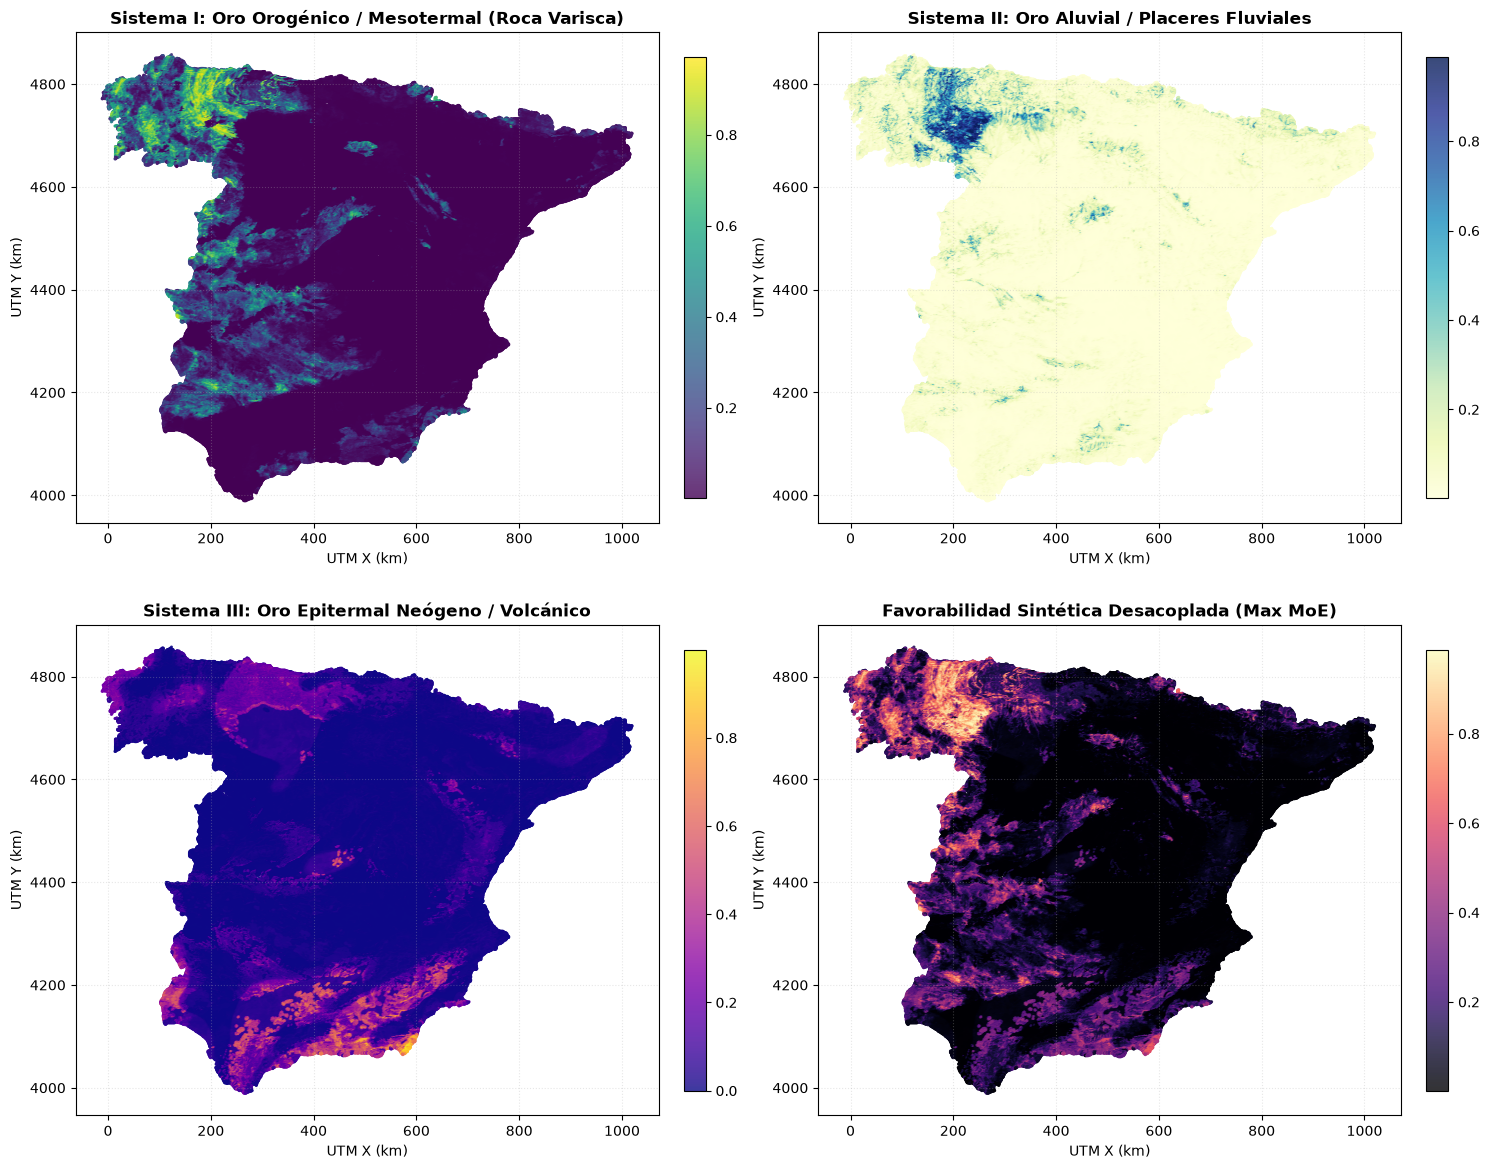

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.flatten()

# Cargar coordenadas espaciales
grid_xy = data.grid.set_index('cell_id')
x_c = grid_xy.loc[X_all.index, 'x_center'] / 1000.0
y_c = grid_xy.loc[X_all.index, 'y_center'] / 1000.0

maps_data = [
    (preds_nat_roca, 'Sistema I: Oro Orogénico / Mesotermal (Roca Varisca)', 'viridis'),
    (preds_nat_aluv, 'Sistema II: Oro Aluvial / Placeres Fluviales', 'YlGnBu'),
    (preds_nat_epith_norm, 'Sistema III: Oro Epitermal Neógeno / Volcánico', 'plasma'),
    (score_desacoplado_nacional, 'Favorabilidad Sintética Desacoplada (Max MoE)', 'magma')
]

for idx, (vals, title, cmap) in enumerate(maps_data):
    ax = axes[idx]
    sc = ax.scatter(x_c, y_c, c=vals, cmap=cmap, s=1.5, alpha=0.8, rasterized=True)
    plt.colorbar(sc, ax=ax, fraction=0.035, pad=0.04)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('UTM X (km)')
    ax.set_ylabel('UTM Y (km)')
    ax.set_aspect('equal')
    ax.grid(True, linestyle=':', alpha=0.3)

plt.tight_layout()
plt.show()


## 10. Sellado y Persistencia de Artefactos de la Fase 26

In [9]:
rep_dir = ROOT / 'reports/reentrenamiento_desacoplamiento_sistemas_20261022'
rep_dir.mkdir(parents=True, exist_ok=True)

# Guardar favorabilidad nacional desacoplada
df_fav_desac = pd.DataFrame({
    'cell_id': X_all.index,
    'favorabilidad_desacoplada_max': score_desacoplado_nacional,
    'favorabilidad_orogenico_roca': preds_nat_roca,
    'favorabilidad_aluvial_placer': preds_nat_aluv,
    'favorabilidad_epitermal_neogeno': preds_nat_epith_norm,
    'favorabilidad_monolito_global': preds_nat_mono,
    'trampa_valle_aluvial': X_all['trampa_valle_aluvial'].values,
    'vector_epitermal_hidrotermal': X_all['vector_epitermal_hidrotermal'].values
})
fav_path = rep_dir / 'favorabilidad_nacional_desacoplamiento.parquet'
df_fav_desac.to_parquet(fav_path, index=False)
print(f"Favorabilidad desacoplada guardada: {fav_path} ({len(df_fav_desac):,} celdas)")

# Guardar tablas de evolución y detalles de rotación
df_evolution.to_csv(rep_dir / 'comparativa_evolucion_modelos.csv', index=False)
df_rot_details_desac.to_csv(rep_dir / 'detalle_rotaciones_ciegas_desacopladas.csv', index=False)

with open(rep_dir / 'resumen_metricas_desacoplamiento.json', 'w', encoding='utf-8') as f:
    json.dump({
        'in_sample': {
            'captured_01': m_nat_desac['captured_deposits_at_01'],
            'captured_05': m_nat_desac['captured_deposits_at_05'],
            'captured_10': m_nat_desac['captured_deposits_at_10'],
            'captured_20': m_nat_desac['captured_deposits_at_20'],
        },
        'blind_out_of_fold': summary_desac_rot
    }, f, indent=2)

print(f"Artefactos y métricas persistidos exitosamente en: {rep_dir}")


Favorabilidad desacoplada guardada: C:\Users\Lenovo\Desktop\PROYECTO IA\GeoAI\GeoAI\reports\reentrenamiento_desacoplamiento_sistemas_20261022\favorabilidad_nacional_desacoplamiento.parquet (478,443 celdas)
Artefactos y métricas persistidos exitosamente en: C:\Users\Lenovo\Desktop\PROYECTO IA\GeoAI\GeoAI\reports\reentrenamiento_desacoplamiento_sistemas_20261022


# 11. Control añadido: desacoplamiento desde la base original de 64 variables

Esta ampliación conserva las celdas 1–18 anteriores y sus resultados históricos. **Las celdas nuevas se ejecutan en un kernel independiente**; no dependen de objetos ni de etiquetas heurísticas calculados arriba. Se conserva una copia byte a byte del notebook anterior en la nueva carpeta de resultados.

Pregunta: ¿el desacoplamiento aporta valor por sí mismo, o la diferencia depende de las variables añadidas después de NB19? Se ajustan cuatro opciones:

| Variables | Global | Desacoplado por sistemas |
| --- | --- | --- |
| 64 originales | global64 | max3_64 |
| 95 corregidas | global95 | max3_95 |

No se presupone que 64 variables sean más sólidas: se comprueba. El endpoint principal se fija antes de esta ejecución: depósitos recuperados al priorizar el5% de las celdas reservadas; contraste max3_64 menos global64. Los territorios ya se han explorado en otros experimentos, por lo que esta comparación es exploratoria.

El desacoplado conserva un componente global con todas las P (también las de sistema no resuelto) y especialistas primario no epitermal, aluvial y epitermal. Se usa el máximo de sus percentiles frente al fondo U. Las etiquetas se auditan y las CDF se aprenden mediante tres pliegues espaciales internos, únicamente dentro del entrenamiento. No se repite el min–max sobre la reserva ni la asignación epitermal por provincia de la sección histórica.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Markdown, Image

ROOT_CONTROL = Path.cwd().resolve()
if ROOT_CONTROL.name == 'notebooks':
    ROOT_CONTROL = ROOT_CONTROL.parent
sys.path.insert(0, str(ROOT_CONTROL / 'src'))
from geoau.base_decoupling_control import BaseDecouplingControl

control64 = BaseDecouplingControl(ROOT_CONTROL, output='reports/control_desacoplamiento_base64_nb26_20261022')
display(pd.Series(control64.cfg).to_frame('diseño_fijado'))
display(pd.read_csv(control64.output / 'resumen_tipologias.csv'))

2026-10-22T18:07:58+00:00 Control NB26 fijado: cuatro opciones, 5 CV, 7 rotaciones y reentrenamiento nacional


,diseño_fijado
seed,42
bags,8
inner_folds,3
buffer_m,15000
weight_step,0.1
minimum_specialist_P,2
prediction_batch_size,25000
default_national_method,max3_64
selection_metric,none; four methods fixed; maximum has no learn...
classifier,"{'n_estimators': 150, 'max_depth': 5, 'num_lea..."


,grupo,celdas_P
0,primario,263
1,primario_otro,259
2,aluvial,310
3,epitermal,4
4,no_resuelto,98
5,mixto,7


## 11.1. Matrices y condiciones comunes

La matriz64 se carga directamente de las56 variables físicas aprobadas y las ocho clases geoquímicas originales. Se comprueba que sea idéntica a las primeras64 de la matriz95 corregida de NB27. No recibe índices nuevos ni cálculos auxiliares de las31 variables adicionales.

Se conserva la receta nacional original: ocho LightGBM,150 árboles, profundidad5,24 hojas, learning_rate0.04 y colsample_bytree1.0; ocho miembros tanto para global como para cada especialista disponible. El epitermal mantiene80 árboles/profundidad3/8 hojas por sus escasas P. Por componente y miembro,64 y95 reciben exactamente las mismas filas, su orden, pesos y semillas. U:P=3:1 sin reemplazo; las P de otro sistema tampoco se convierten en U.

En cada miembro, imputación, escalado y codificación se ajustan con su entrenamiento. Solo95 calcula el índice de pathfinders con estadísticas del entrenamiento. Se conserva el tratamiento categórico de las ocho clases del atlas en ambas matrices.

In [2]:
display(control64.prepare_features())
display(pd.read_csv(control64.output / 'contrato_variables_64_95.csv').groupby('matrix').size().rename('variables_de_entrada'))

2026-10-22T18:08:01+00:00 478443 celdas: base de 64 exacta y control extendido de 95; 664 P


,variables,originales
matrix,,
64,64,64
95,95,64


matrix
64    64
95    95
Name: variables_de_entrada, dtype: int64

## 11.2. Evaluación mediante CV espacial

Se utilizan las mismas cinco particiones congeladas, bloques de50km y buffer de15km. El global64 debe reproducir las predicciones de la evaluación de la receta nacional anterior. Se evalúan ROC-AUC, Average Precision, área PR trapezoidal, Brier P/U y recuperación de P al1/5/10%.

Las CDF internas convierten los scores de los componentes en percentiles frente a U de entrenamiento; no son probabilidades calibradas. Se exporta un diagnóstico del global normalizado porque la normalización por pliegue puede cambiar métricas agrupadas entre pliegues, aunque preserve el orden dentro de cada uno.

In [3]:
cv_control64 = control64.evaluate_cv()
display(cv_control64)
display(pd.read_csv(control64.output / 'cv_cdf_diagnostic.csv'))

2026-10-22T18:08:02+00:00 Iniciando cv/0: 450 P; 503 celdas evaluadas


2026-10-22T18:08:46+00:00 cv/0/inner_0: 358 P, 48 ajustes reales, 28.5s


2026-10-22T18:09:18+00:00 cv/0/inner_1: 212 P, 48 ajustes reales, 27.6s


2026-10-22T18:09:47+00:00 cv/0/inner_2: 109 P, 48 ajustes reales, 25.1s


2026-10-22T18:10:34+00:00 cv/0/outer: 450 P, 48 ajustes reales, 42.4s


...

2026-10-22T18:20:08+00:00 cv/4/inner_2: 296 P, 48 ajustes reales, 28.5s


2026-10-22T18:20:55+00:00 cv/4/outer: 444 P, 48 ajustes reales, 43.5s


2026-10-22T18:20:56+00:00 CV 5/5 terminada


,method,roc_auc,average_precision,pr_auc_trapezoid,brier_loss,positive_cell_recovery_at_01,positive_cell_recovery_at_05,positive_cell_recovery_at_10
0,global64,0.900231,0.746536,0.746068,0.116317,0.038156,0.178060,0.335453
1,max3_64,0.884688,0.725764,0.725191,0.332645,0.038156,0.173291,0.337043
2,global95,0.891763,0.697352,0.696679,0.132002,0.031797,0.165342,0.313196
3,max3_95,0.881779,0.679545,0.678951,0.309655,0.033386,0.168521,0.306836


,method,roc_auc,average_precision,pr_auc_trapezoid,brier_loss,positive_cell_recovery_at_01,positive_cell_recovery_at_05,positive_cell_recovery_at_10
0,cdf_global64,0.899406,0.748720,0.748321,0.262980,0.036566,0.179650,0.341812
1,cdf_global95,0.888708,0.693617,0.693008,0.257055,0.033386,0.163752,0.308426


## 11.3. Rotaciones de distritos y atribución de diferencias

Los distritos son las agrupaciones de indicios y depósitos del inventario empleadas para representar zonas mineralizadas. Se reservan siete grupos, sus bloques completos y15km de entorno, y se puntúan todas las celdas reservadas. Cada uno de los45 depósitos se cuenta una sola vez, con presupuestos exactos del1/5/10/20% y desempate por cell_id.

Los cuatro contrastes separan el efecto de desacoplar a64 o95 variables y el de añadir31 variables en global o desacoplado. Se muestran intervalos exploratorios con10000 remuestreos pareados de los siete grupos, junto con la esperanza aleatoria que considera huellas multicelda. No se usan las reservas externas para ajustar modelos, normalización, pesos ni hiperparámetros.

In [4]:
rotaciones_control64 = control64.evaluate_rotations()
display(rotaciones_control64[['method','n_deposits','captured_01','captured_05','captured_10','captured_20']])
display(pd.read_csv(control64.output / 'random_summary.csv'))
contrastes_control64 = pd.read_csv(control64.output / 'factorial_contrasts.csv')
display(contrastes_control64.loc[contrastes_control64.budget_percent.eq(5)])

2026-10-22T18:20:58+00:00 Iniciando rotation/0: 559 P; 9290 celdas evaluadas


2026-10-22T18:21:50+00:00 rotation/0/inner_0: 251 P, 48 ajustes reales, 32.9s


2026-10-22T18:22:28+00:00 rotation/0/inner_1: 138 P, 64 ajustes reales, 32.7s


2026-10-22T18:23:11+00:00 rotation/0/inner_2: 416 P, 64 ajustes reales, 37.3s


2026-10-22T18:24:16+00:00 rotation/0/outer: 559 P, 64 ajustes reales, 59.1s


...

2026-10-22T18:45:21+00:00 rotation/6/outer: 516 P, 48 ajustes reales, 57.7s


2026-10-22T18:45:22+00:00 Rotación 7/7 terminada


,method,n_deposits,captured_01,captured_05,captured_10,captured_20
0,global64,45,3,6,9,16
1,max3_64,45,1,5,15,19
2,global95,45,0,6,13,17
3,max3_95,45,2,8,12,18


,budget_percent,expected_deposits
0,1,1.315466
1,5,6.160566
2,10,11.434624
3,20,19.909472


,contrast,method_A,method_B,budget_percent,captured_A,captured_B,delta_captured,delta_recovery_pp,ci025_pp,ci975_pp,delta_cv_auc,delta_cv_ap
1,desacoplamiento_con_64,max3_64,global64,5,5,6,-1,-2.222222,-13.043478,8.888889,-0.015544,-0.020772
5,desacoplamiento_con_95,max3_95,global95,5,8,6,2,4.444444,-4.545455,11.363636,-0.009984,-0.017807
9,variables_en_global,global95,global64,5,6,6,0,0.000000,-6.382979,6.818182,-0.008468,-0.049183
13,variables_en_desacoplado,max3_95,max3_64,5,8,5,3,6.666667,0.000000,15.217391,-0.002908,-0.046218


## 11.4. Reentrenamiento nacional real

Se reajustan los ocho miembros de cada componente64/95 con todas las664 P elegibles y U admisibles nacionales. Se guardan pipelines, CDF internas, scores, dispersión de miembros, importancias y cuatro GeoTIFF. El bundle conserva el contrato de variables para reproducir la inferencia.

`max3_64` es el mapa experimental fijado para estudiar la base simplificada. Los otros tres se conservan para comparación. Las métricas sobre presencias del mapa nacional son descriptivas in-sample; no sustituyen las rotaciones o CV. Esta sección no cambia el modelo servido por la aplicación.

In [5]:
nacional_control64 = control64.fit_national()
display(nacional_control64[['method','n_deposits','captured_deposits_at_01','captured_deposits_at_05','captured_deposits_at_10','captured_deposits_at_20']])
print('Bundle nacional:', control64.output / 'partitions/national_0/model.joblib')
print('Mapa experimental64:', control64.output / 'maps/NB26_control_max3_64_score.tif')

2026-10-22T18:45:23+00:00 Iniciando national/0: 664 P; 478443 celdas evaluadas


2026-10-22T18:46:19+00:00 national/0/inner_0: 390 P, 64 ajustes reales, 36.0s


2026-10-22T18:46:58+00:00 national/0/inner_1: 202 P, 64 ajustes reales, 33.8s


2026-10-22T18:47:39+00:00 national/0/inner_2: 341 P, 48 ajustes reales, 36.0s


2026-10-22T18:48:11+00:00 Nacional: miembro 1/8 ajustado y puntuado con 64 y 95 variables


...

2026-10-22T18:51:19+00:00 Nacional: miembro 8/8 ajustado y puntuado con 64 y 95 variables


2026-10-22T18:51:21+00:00 national/0/outer: 664 P, 64 ajustes reales, 216.8s


2026-10-22T18:51:28+00:00 Reentrenamiento nacional terminado: cuatro mapas, ocho componentes y modelos persistidos


,method,n_deposits,captured_deposits_at_01,captured_deposits_at_05,captured_deposits_at_10,captured_deposits_at_20
0,global64,45,22,38,42,42
1,max3_64,45,26,41,42,45
2,global95,45,29,43,45,45
3,max3_95,45,32,44,45,45


Bundle nacional: C:\Users\Lenovo\Desktop\PROYECTO IA\GeoAI\GeoAI\reports\control_desacoplamiento_base64_nb26_20261022\partitions\national_0\model.joblib
Mapa experimental64: C:\Users\Lenovo\Desktop\PROYECTO IA\GeoAI\GeoAI\reports\control_desacoplamiento_base64_nb26_20261022\maps\NB26_control_max3_64_score.tif


## 11.5. Verificaciones, resultados y reproducción

Se verifican las celdas históricas, fuentes, contratos de64/95 variables, muestras P/U pareadas, pesos, buffers, CDF internas y predicciones de los trece bundles serializados. El global64 debe coincidir con la receta nacional anterior en CV y las siete rotaciones. Los resultados y la conclusión se generan con los archivos de esta ejecución.

Para ejecutar únicamente esta ampliación: `.venv-fase-a/Scripts/python.exe scripts/append_control_64_nb26.py`. No es necesario volver a ejecutar las celdas históricas del comienzo. La copia original permite comprobar su hash anterior, conservado en los manifiestos históricos de NB27/NB29.

2026-10-22T18:53:19+00:00 Control validado: 11854 comprobaciones; 2832 ajustes reales


,validacion
passed,True
n_checks,11854
n_actual_fits,2832
n_national_fits,64
original_global64_reproduced,True
historical_cells_preserved,True


Matplotlib is building the font cache; this may take a moment.


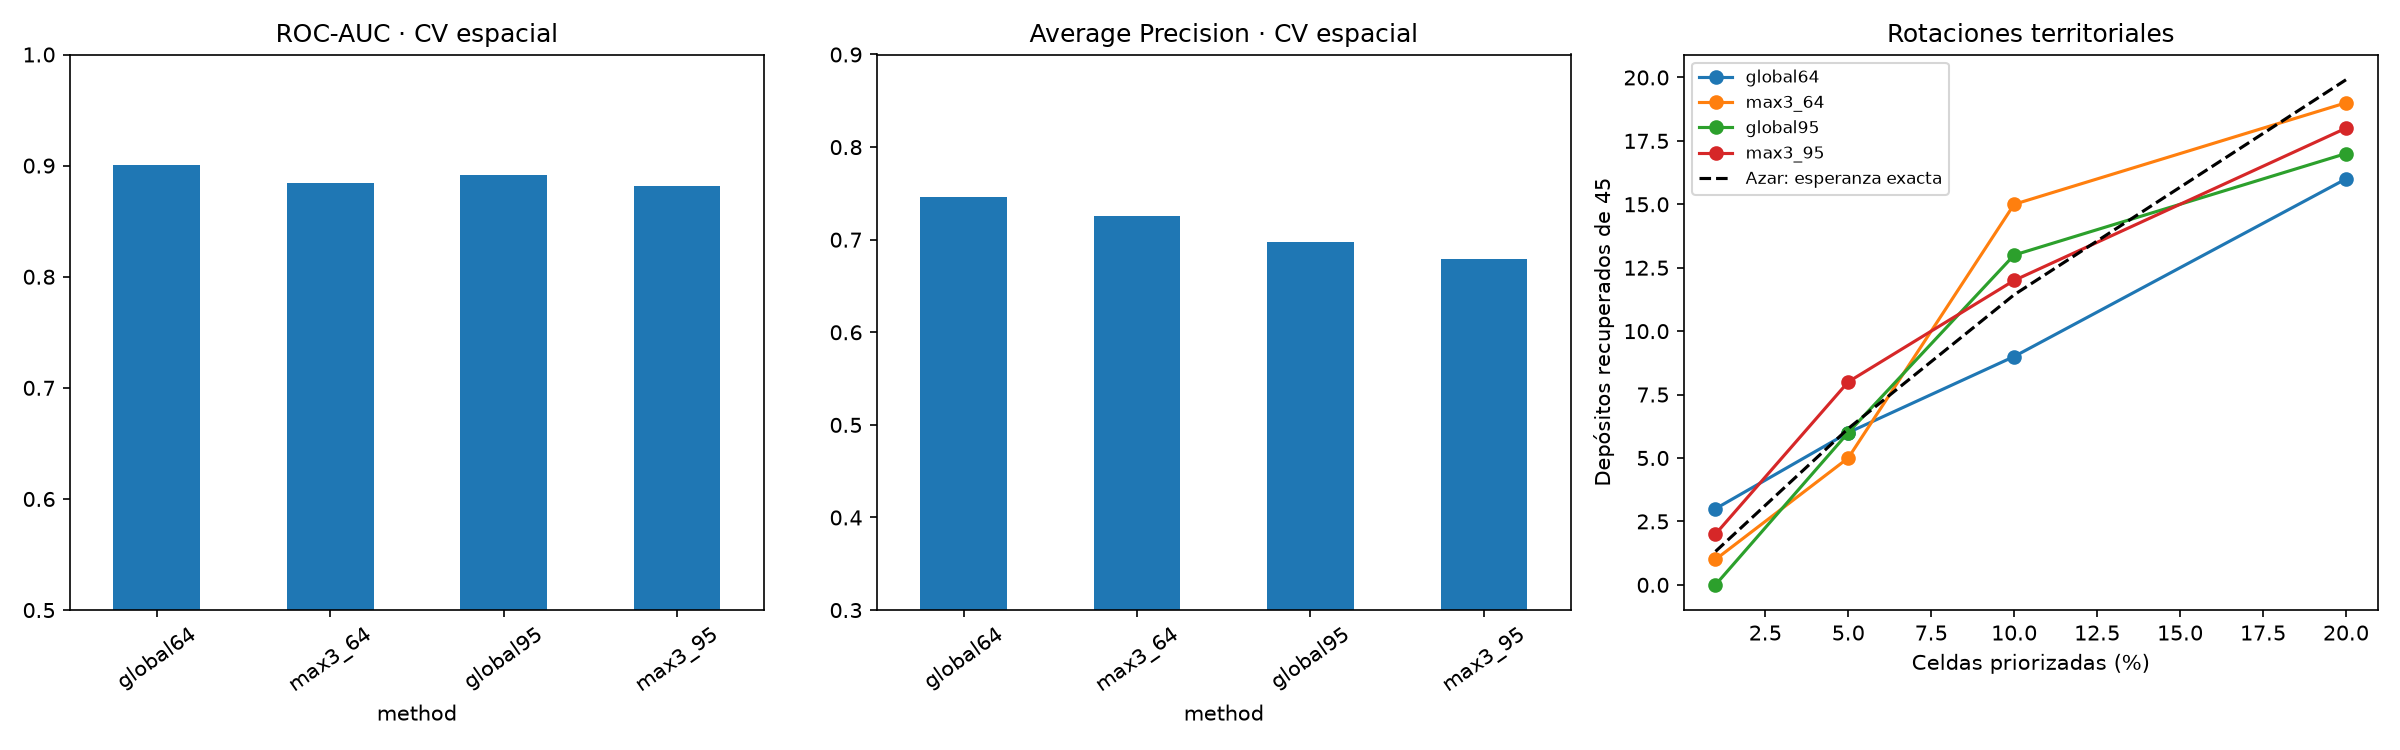

2026-10-22T18:53:27+00:00 Control NB26 ejecutado, reentrenado y sellado. Informe: C:\Users\Lenovo\Desktop\PROYECTO IA\GeoAI\GeoAI\informes\control_desacoplamiento_base64_nb26_20261022\INFORME_CONTROL_64_95.md


# Control factorial de NB26: base original64 y ampliada95

Fecha: 22/10/2026. Sección añadida al final de NB26 por petición expresa. Resultados realmente ejecutados.

## Resultado principal

Con 64 variables, desacoplar cambia la captura al 5% en **-1 depósitos de 45** frente al global original: 5 frente a 6. Diferencia: -2.22 puntos porcentuales; intervalo exploratorio por grupos [-13.04, 8.89].

La comparación utiliza cuatro entrenamientos nuevos y emparejados. `global64` reproduce las predicciones de la receta nacional evaluada, no una aproximación con otros hiperparámetros. La complejidad de una matriz menor no garantiza por sí misma mejores resultados; se decide a partir de estos contrastes.



Informe: C:\Users\Lenovo\Desktop\PROYECTO IA\GeoAI\GeoAI\informes\control_desacoplamiento_base64_nb26_20261022\INFORME_CONTROL_64_95.md


In [6]:
validacion_control64 = control64.validate()
display(pd.Series(validacion_control64).to_frame('validacion'))
display(Image(filename=str(control64.make_figures())))
informe_control64 = control64.write_report()
control64.seal(informe_control64)
display(Markdown(informe_control64.read_text(encoding='utf-8').split('## Qué se compara')[0]))
print('Informe:', informe_control64)